#Data PreProcessing



In [ ]:
import yfinance as yf

ticker = yf.Ticker("BBRI.JK")
df = ticker.history(start="2019-01-01", end="2025-12-31")
df[['Open','High','Low','Close']].to_csv("BBRI_2019_2025.csv")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM

In [ ]:
data_saham = pd.read_csv('/content/BBRI_2019_2025.csv', parse_dates=['Date'], sep=',', index_col='Date')


In [ ]:
data_saham

,Open,High,Low,Close
Date,,,,
2019-01-01 00:00:00+07:00,2286.933838,2286.933838,2286.933838,2286.933838
2019-01-02 00:00:00+07:00,2255.691406,2274.436737,2243.194575,2255.691406
2019-01-03 00:00:00+07:00,2236.946352,2274.437018,2236.946352,2261.940186
2019-01-04 00:00:00+07:00,2261.940006,2286.933838,2255.691506,2286.933838
2019-01-07 00:00:00+07:00,2311.927670,2318.176002,2286.933838,2286.933838
...,...,...,...,...
2025-12-22 00:00:00+07:00,3633.362420,3642.999986,3614.087287,3623.724854
2025-12-23 00:00:00+07:00,3623.724982,3643.000115,3594.812283,3633.362549
2025-12-24 00:00:00+07:00,3633.362549,3652.637682,3614.087416,3633.362549


Text(0.5, 1.0, 'Harga Buka Saham BBRI')

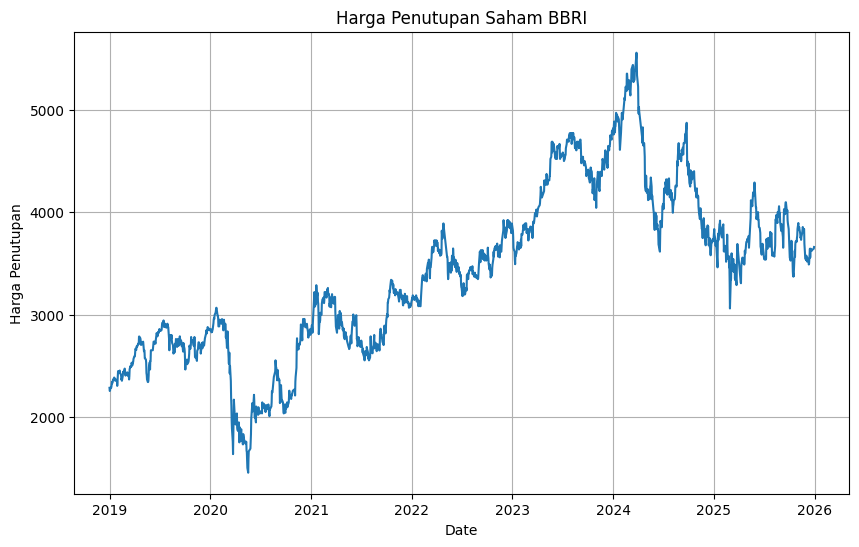

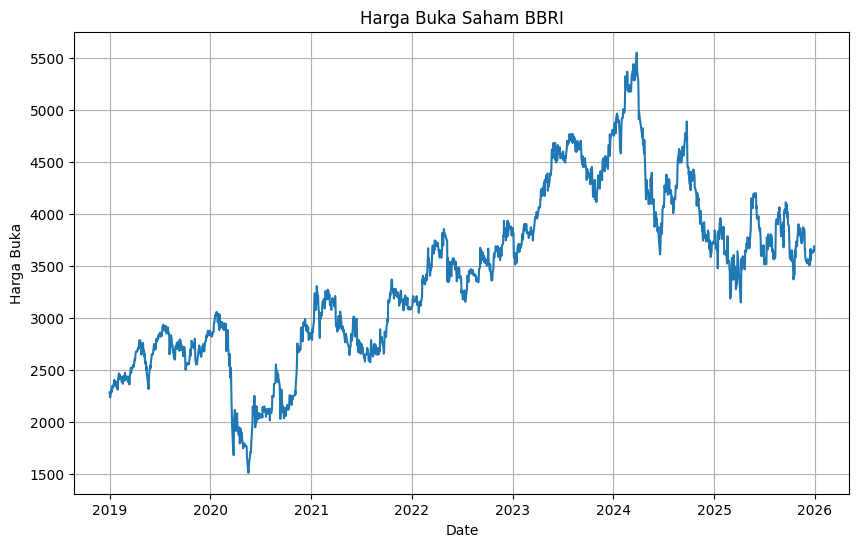

In [ ]:
#Satu Fitur
df_close = data_saham['Close']
df_open = data_saham['Open']
df_high = data_saham['High']
df_low = data_saham['Low']

#Dua Fitur
df_open_close = data_saham[['Open','Close']]
df_high_close = data_saham[['High','Close']]
df_low_close = data_saham[['Low','Close']]
df_open_high = data_saham[['Open','High']]
df_open_low = data_saham[['Open','Low']]
df_high_low = data_saham[['High','Low']]

#Tiga Fitur
df_open_high_close = data_saham[['Open','High','Close']]
df_open_low_close = data_saham[['Open','Low','Close']]
df_high_low_close = data_saham[['High','Low','Close']]
df_open_high_low = data_saham[['Open','High','Low']]

#Empat Fitur
df_open_high_low_close = data_saham[['Open','High','Low','Close']]

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_close)
plt.xlabel('Date')
plt.ylabel('Harga Penutupan')
plt.title('Harga Penutupan Saham BBRI')

plt.figure(figsize=(10,6))
plt.grid()
plt.plot(df_open)
plt.xlabel('Date')
plt.ylabel('Harga Buka')
plt.title('Harga Buka Saham BBRI')

In [ ]:
df_high

,High
Date,
2019-01-01 00:00:00+07:00,2286.933838
2019-01-02 00:00:00+07:00,2274.436737
2019-01-03 00:00:00+07:00,2274.437018
2019-01-04 00:00:00+07:00,2286.933838
2019-01-07 00:00:00+07:00,2318.176002
...,...
2025-12-22 00:00:00+07:00,3642.999986
2025-12-23 00:00:00+07:00,3643.000115
2025-12-24 00:00:00+07:00,3652.637682


<Figure size 640x480 with 0 Axes>

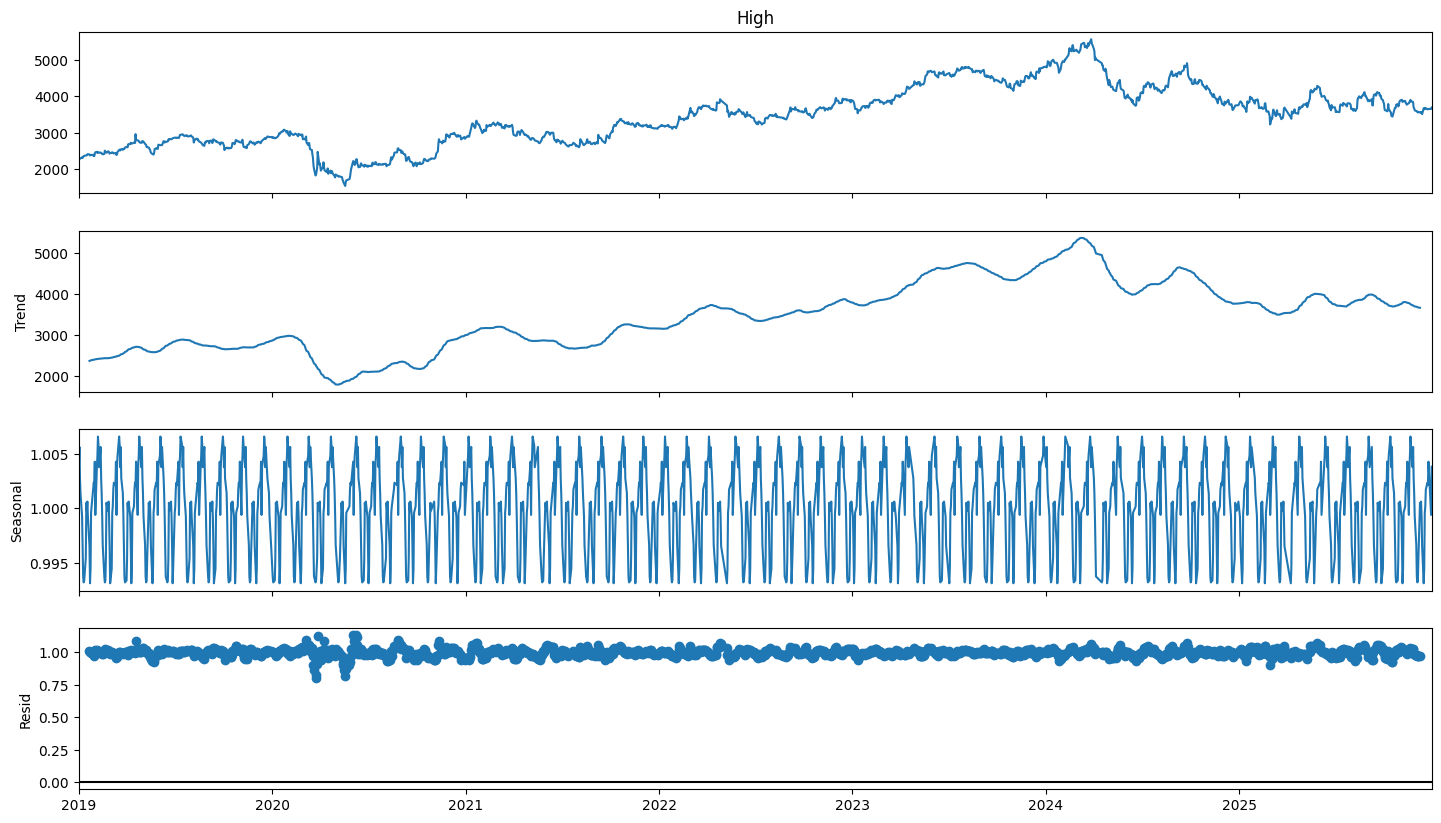

In [ ]:
#GANTI
result = seasonal_decompose(df_high, model='multiplicative',period=28)
fig = plt.figure()
fig = result.plot()
fig.set_size_inches(16, 9)

Text(0.5, 1.0, 'Transformed data')

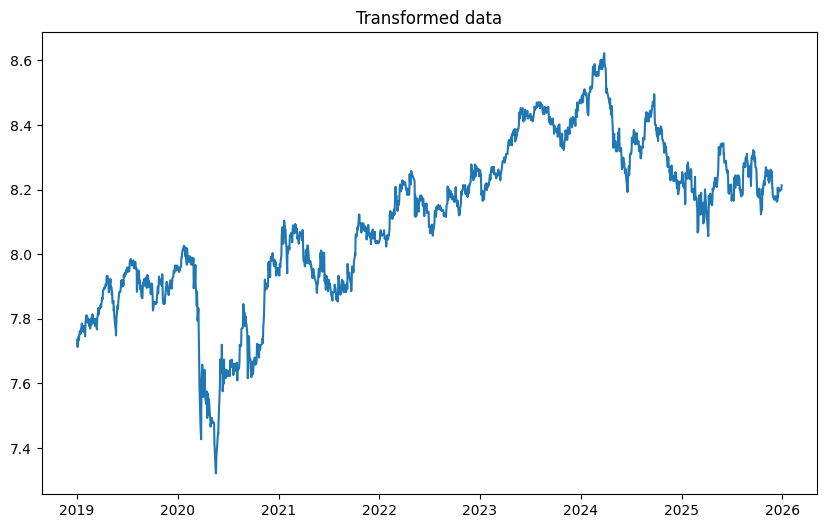

In [ ]:
#Untuk mengecilkan skala menggunakan fungsi Log tapi masih mempertahankan karakter data
df_close_log = np.log(df_close)
df_open_log = np.log(df_open)
df_high_log = np.log(df_high)
df_low_log = np.log(df_low)
df_open_close_log = np.log(df_open_close)
df_high_close_log = np.log(df_high_close)
df_low_close_log = np.log(df_low_close)
df_open_high_log = np.log(df_open_high)
df_open_low_log = np.log(df_open_low)
df_high_low_log = np.log(df_high_low)
df_open_high_close_log = np.log(df_open_high_close)
df_open_low_close_log = np.log(df_open_low_close)
df_high_low_close_log = np.log(df_high_low_close)
df_open_high_low_log = np.log(df_open_high_low)
df_open_high_low_close_log = np.log(df_open_high_low_close)

plt.figure(figsize = (10,6))
plt.plot(df_open_log)
plt.title('Transformed data')

In [ ]:
from sklearn.model_selection import train_test_split

# Mengumpulkan semua dataset
datasets = {
    "open": df_open_log,
    "high": df_high_log,
    "low": df_low_log,
    "close": df_close_log,

    "open_close": df_open_close_log,
    "open_high": df_open_high_log,
    "open_low": df_open_low_log,
    "high_low": df_high_low_log,
    "low_close": df_low_close_log,
    "high_close": df_high_close_log,

    "open_high_low": df_open_high_low_log,
    "open_low_close": df_open_low_close_log,
    "open_high_close": df_open_high_close_log,
    "high_low_close": df_high_low_close_log,

    "open_high_low_close": df_open_high_low_close_log
}

splits = {}

for name, df in datasets.items():

    # split train dan sementara (val+test)
    train, temp = train_test_split(df, test_size=0.30, shuffle=False)

    # split validation dan test
    val, test = train_test_split(temp, test_size=0.50, shuffle=False)

    splits[name] = {
        "train": train,
        "validation": val,
        "test": test
    }

# Satu fitur
train_open = splits["open"]["train"]
val_open = splits["open"]["validation"]
test_open = splits["open"]["test"]

train_high = splits["high"]["train"]
val_high = splits["high"]["validation"]
test_high = splits["high"]["test"]

train_low = splits["low"]["train"]
val_low = splits["low"]["validation"]
test_low = splits["low"]["test"]

train_close = splits["close"]["train"]
val_close = splits["close"]["validation"]
test_close = splits["close"]["test"]

# Dua Fitur
train_open_close = splits["open_close"]["train"]
val_open_close = splits["open_close"]["validation"]
test_open_close = splits["open_close"]["test"]

train_open_high = splits["open_high"]["train"]
val_open_high = splits["open_high"]["validation"]
test_open_high = splits["open_high"]["test"]

train_open_low = splits["open_low"]["train"]
val_open_low = splits["open_low"]["validation"]
test_open_low = splits["open_low"]["test"]

train_high_low = splits["high_low"]["train"]
val_high_low = splits["high_low"]["validation"]
test_high_low = splits["high_low"]["test"]

train_high_close = splits["high_close"]["train"]
val_high_close = splits["high_close"]["validation"]
test_high_close = splits["high_close"]["test"]

train_low_close = splits["low_close"]["train"]
val_low_close = splits["low_close"]["validation"]
test_low_close = splits["low_close"]["test"]

# Tiga fitur
train_open_high_low = splits["open_high_low"]["train"]
val_open_high_low = splits["open_high_low"]["validation"]
test_open_high_low = splits["open_high_low"]["test"]

train_open_high_close = splits["open_high_close"]["train"]
val_open_high_close = splits["open_high_close"]["validation"]
test_open_high_close = splits["open_high_close"]["test"]

train_open_low_close = splits["open_low_close"]["train"]
val_open_low_close = splits["open_low_close"]["validation"]
test_open_low_close = splits["open_low_close"]["test"]

train_high_low_close = splits["high_low_close"]["train"]
val_high_low_close = splits["high_low_close"]["validation"]
test_high_low_close = splits["high_low_close"]["test"]

# Empat Fitur
train_open_high_low_close = splits["open_high_low_close"]["train"]
val_open_high_low_close = splits["open_high_low_close"]["validation"]
test_open_high_low_close = splits["open_high_low_close"]["test"]

In [ ]:
train_open

,Open
Date,
2019-01-01 00:00:00+07:00,7.734967
2019-01-02 00:00:00+07:00,7.721212
2019-01-03 00:00:00+07:00,7.712867
2019-01-04 00:00:00+07:00,7.723978
2019-01-07 00:00:00+07:00,7.745837
...,...
2023-10-27 00:00:00+07:00,8.328961
2023-10-30 00:00:00+07:00,8.335004
2023-10-31 00:00:00+07:00,8.335004


In [ ]:
val_open

,Open
Date,
2023-11-03 00:00:00+07:00,8.343999
2023-11-06 00:00:00+07:00,8.358814
2023-11-07 00:00:00+07:00,8.383028
2023-11-08 00:00:00+07:00,8.378232
2023-11-09 00:00:00+07:00,8.383028
...,...
2024-11-21 00:00:00+07:00,8.235718
2024-11-22 00:00:00+07:00,8.228684
2024-11-25 00:00:00+07:00,8.267904


In [ ]:
test_open

,Open
Date,
2024-11-29 00:00:00+07:00,8.235718
2024-12-02 00:00:00+07:00,8.233379
2024-12-03 00:00:00+07:00,8.226328
2024-12-04 00:00:00+07:00,8.226328
2024-12-05 00:00:00+07:00,8.242703
...,...
2025-12-22 00:00:00+07:00,8.197914
2025-12-23 00:00:00+07:00,8.195258
2025-12-24 00:00:00+07:00,8.197914


In [ ]:
train_open_close

,Open,Close
Date,,
2019-01-01 00:00:00+07:00,7.734967,7.734967
2019-01-02 00:00:00+07:00,7.721212,7.721212
2019-01-03 00:00:00+07:00,7.712867,7.723978
2019-01-04 00:00:00+07:00,7.723978,7.734967
2019-01-07 00:00:00+07:00,7.745837,7.734967
...,...,...
2023-10-27 00:00:00+07:00,8.328961,8.339012
2023-10-30 00:00:00+07:00,8.335004,8.339012
2023-10-31 00:00:00+07:00,8.335004,8.330979


In [ ]:
# Standarisasi data MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

scaled_splits = {}

for name, data in splits.items():

    train = data["train"]
    val = data["validation"]
    test = data["test"]

    scaler = MinMaxScaler()

    # Ensure the input to scaler is 2-dimensional
    # If it's a pandas Series, convert it to a DataFrame with a single column
    if isinstance(train, pd.Series):
        train = train.to_frame()
        val = val.to_frame()
        test = test.to_frame()

    # fit hanya pada train
    scaler.fit(train)

    # transform
    train_scaled = scaler.transform(train)
    val_scaled = scaler.transform(val)
    test_scaled = scaler.transform(test)

    scaled_splits[name] = {
        "train": train_scaled,
        "validation": val_scaled,
        "test": test_scaled,
        "scaler": scaler
    }

# Satu fitur
train_scaled_open = scaled_splits["open"]["train"]
val_scaled_open = scaled_splits["open"]["validation"]
test_scaled_open = scaled_splits["open"]["test"]

train_scaled_high = scaled_splits["high"]["train"]
val_scaled_high = scaled_splits["high"]["validation"]
test_scaled_high = scaled_splits["high"]["test"]

train_scaled_low = scaled_splits["low"]["train"]
val_scaled_low = scaled_splits["low"]["validation"]
test_scaled_low = scaled_splits["low"]["test"]

train_scaled_close = scaled_splits["close"]["train"]
val_scaled_close = scaled_splits["close"]["validation"]
test_scaled_close = scaled_splits["close"]["test"]

# Dua Fitur
train_scaled_open_close = scaled_splits["open_close"]["train"]
val_scaled_open_close = scaled_splits["open_close"]["validation"]
test_scaled_open_close = scaled_splits["open_close"]["test"]

train_scaled_open_high = scaled_splits["open_high"]["train"]
val_scaled_open_high = scaled_splits["open_high"]["validation"]
test_scaled_open_high = scaled_splits["open_high"]["test"]

train_scaled_open_low = scaled_splits["open_low"]["train"]
val_scaled_open_low = scaled_splits["open_low"]["validation"]
test_scaled_open_low = scaled_splits["open_low"]["test"]

train_scaled_high_low = scaled_splits["high_low"]["train"]
val_scaled_high_low = scaled_splits["high_low"]["validation"]
test_scaled_high_low = scaled_splits["high_low"]["test"]

train_scaled_high_close = scaled_splits["high_close"]["train"]
val_scaled_high_close = scaled_splits["high_close"]["validation"]
test_scaled_high_close = scaled_splits["high_close"]["test"]

train_scaled_low_close = scaled_splits["low_close"]["train"]
val_scaled_low_close = scaled_splits["low_close"]["validation"]
test_scaled_low_close = scaled_splits["low_close"]["test"]

# Tiga Fitur
train_scaled_open_high_low = scaled_splits["open_high_low"]["train"]
val_scaled_open_high_low = scaled_splits["open_high_low"]["validation"]
test_scaled_open_high_low = scaled_splits["open_high_low"]["test"]

train_scaled_open_high_close = scaled_splits["open_high_close"]["train"]
val_scaled_open_high_close = scaled_splits["open_high_close"]["validation"]
test_scaled_open_high_close = scaled_splits["open_high_close"]["test"]

train_scaled_open_low_close = scaled_splits["open_low_close"]["train"]
val_scaled_open_low_close = scaled_splits["open_low_close"]["validation"]
test_scaled_open_low_close = scaled_splits["open_low_close"]["test"]

train_scaled_high_low_close = scaled_splits["high_low_close"]["train"]
val_scaled_high_low_close = scaled_splits["high_low_close"]["validation"]
test_scaled_high_low_close = scaled_splits["high_low_close"]["test"]

# Empat Fitur
train_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["train"]
val_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["validation"]
test_scaled_open_high_low_close = scaled_splits["open_high_low_close"]["test"]


In [ ]:
train_scaled_close

array([[0.37947944],
       [0.36786761],
       [0.3702029 ],
       ...,
       [0.88261039],
       [0.86019006],
       [0.88939086]])

In [ ]:
test_close.shape

(256,)

In [ ]:
train_scaled_open

array([[0.35991777],
       [0.34793988],
       [0.34067341],
       ...,
       [0.88241388],
       [0.87185892],
       [0.87539148]])

In [ ]:
train_scaled_open_high_low_close

array([[0.35991777, 0.35224726, 0.38330634, 0.37947944],
       [0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       ...,
       [0.88241388, 0.87828658, 0.88634243, 0.88261039],
       [0.87185892, 0.87129167, 0.86392633, 0.86019006],
       [0.87539148, 0.89125252, 0.87779118, 0.88939086]])

In [ ]:
train_scaled_open_high_low_close[1]

array([0.34793988, 0.34747532, 0.3670078 , 0.36786761])

In [ ]:
#GANTI
# Pembentukan Sequence untuk target / y_train (harga pembukaan)

y_high_train = scaled_splits["high"]["train"]

import numpy as np

def create_sequences(features, target, seq_length=7):

    X = []
    y = []

    for i in range(len(features) - seq_length):
        X.append(features[i:i+seq_length])
        y.append(target[i+seq_length])

    return np.array(X), np.array(y)

In [ ]:
#GANTI
# Pembentukan Sequence untuk X_train

train_sequences = {}

for name, data in scaled_splits.items():

    X_data = data["train"]

    X_train, y_train = create_sequences(
        X_data,
        y_high_train,
        seq_length=7
    )

    train_sequences[name] = {
        "X_train": X_train,
        "y_train": y_train
    }

In [ ]:
# Shape sequence train

for name in train_sequences:

    print(name)
    print("X_train:", train_sequences[name]["X_train"].shape)
    print("y_train:", train_sequences[name]["y_train"].shape)
    print()

open
X_train: (1186, 7, 1)
y_train: (1186, 1)

high
X_train: (1186, 7, 1)
y_train: (1186, 1)

low
X_train: (1186, 7, 1)
y_train: (1186, 1)

close
X_train: (1186, 7, 1)
y_train: (1186, 1)

open_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_low
X_train: (1186, 7, 2)
y_train: (1186, 1)

low_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

high_close
X_train: (1186, 7, 2)
y_train: (1186, 1)

open_high_low
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

high_low_close
X_train: (1186, 7, 3)
y_train: (1186, 1)

open_high_low_close
X_train: (1186, 7, 4)
y_train: (1186, 1)



In [ ]:
# Data siap pakai train

# Satu fitur
X_train_open = train_sequences["open"]["X_train"]
y_train_open = train_sequences["open"]["y_train"]

X_train_high = train_sequences["high"]["X_train"]
y_train_high = train_sequences["high"]["y_train"]

X_train_low = train_sequences["low"]["X_train"]
y_train_low = train_sequences["low"]["y_train"]

X_train_close = train_sequences["close"]["X_train"]
y_train_close = train_sequences["close"]["y_train"]

# Dua Fitur
X_train_open_high = train_sequences["open_high"]["X_train"]
y_train_open_high = train_sequences["open_high"]["y_train"]

X_train_open_low = train_sequences["open_low"]["X_train"]
y_train_open_low = train_sequences["open_low"]["y_train"]

X_train_high_low = train_sequences["high_low"]["X_train"]
y_train_high_low = train_sequences["high_low"]["y_train"]

X_train_open_close = train_sequences["open_close"]["X_train"]
y_train_open_close = train_sequences["open_close"]["y_train"]

X_train_high_close = train_sequences["high_close"]["X_train"]
y_train_high_close = train_sequences["high_close"]["y_train"]

X_train_low_close = train_sequences["low_close"]["X_train"]
y_train_low_close = train_sequences["low_close"]["y_train"]

# Tiga Fitur
X_train_open_high_low = train_sequences["open_high_low"]["X_train"]
y_train_open_high_low = train_sequences["open_high_low"]["y_train"]

X_train_open_high_close = train_sequences["open_high_close"]["X_train"]
y_train_open_high_close = train_sequences["open_high_close"]["y_train"]

X_train_open_low_close = train_sequences["open_low_close"]["X_train"]
y_train_open_low_close = train_sequences["open_low_close"]["y_train"]

X_train_high_low_close = train_sequences["high_low_close"]["X_train"]
y_train_high_low_close = train_sequences["high_low_close"]["y_train"]

# Empat Fitur
X_train_open_high_low_close = train_sequences["open_high_low_close"]["X_train"]
y_train_open_high_low_close = train_sequences["open_high_low_close"]["y_train"]


In [ ]:
X_train_open[0]

array([[0.35991777],
       [0.34793988],
       [0.34067341],
       [0.35034872],
       [0.36938281],
       [0.35991777],
       [0.37173315]])

In [ ]:
X_train_open[1]

array([[0.34793988],
       [0.34067341],
       [0.35034872],
       [0.36938281],
       [0.35991777],
       [0.37173315],
       [0.37874604]])

In [ ]:
y_train_open[0]

array([0.37340284])

In [ ]:
X_train_open_high_low_close[0]

array([[0.35991777, 0.35224726, 0.38330634, 0.37947944],
       [0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       [0.35034872, 0.35224726, 0.37169673, 0.37947944],
       [0.36938281, 0.36406371, 0.38330634, 0.37947944],
       [0.35991777, 0.35699308, 0.37635978, 0.38407977],
       [0.37173315, 0.37107751, 0.3901963 , 0.39320605]])

In [ ]:
X_train_open_high_low_close[1]

array([[0.34793988, 0.34747532, 0.3670078 , 0.36786761],
       [0.34067341, 0.34747543, 0.36465363, 0.3702029 ],
       [0.35034872, 0.35224726, 0.37169673, 0.37947944],
       [0.36938281, 0.36406371, 0.38330634, 0.37947944],
       [0.35991777, 0.35699308, 0.37635978, 0.38407977],
       [0.37173315, 0.37107751, 0.3901963 , 0.39320605],
       [0.37874604, 0.37340284, 0.39475838, 0.39998642]])

In [ ]:
y_train

array([[0.37340284],
       [0.37803505],
       [0.38264288],
       ...,
       [0.87828658],
       [0.87129167],
       [0.89125252]])

In [ ]:
print(X_train_open.shape)
print(y_train_open.shape)

print(X_train_open_high_low_close.shape)
print(y_train_open_high_low_close.shape)

(1186, 7, 1)
(1186, 1)
(1186, 7, 4)
(1186, 1)


In [ ]:
#GANTI
# Pembentukan Sequnce data Validation dan data test

y_high_val = scaled_splits["high"]["validation"]
y_high_test = scaled_splits["high"]["test"]

val_sequences = {}
test_sequences = {}

for name, data in scaled_splits.items():

    val_data = data["validation"]
    test_data = data["test"]

    X_val, y_val = create_sequences(val_data, y_high_val, seq_length=7)
    X_test, y_test = create_sequences(test_data, y_high_test, seq_length=7)

    val_sequences[name] = {
        "X_val": X_val,
        "y_val": y_val
    }

    test_sequences[name] = {
        "X_test": X_test,
        "y_test": y_test
    }

In [ ]:
# Shape sequence validation

for name in val_sequences:

    print(name)
    print("X_val:", val_sequences[name]["X_val"].shape)
    print("y_val:", val_sequences[name]["y_val"].shape)
    print()

open
X_val: (249, 7, 1)
y_val: (249, 1)

high
X_val: (249, 7, 1)
y_val: (249, 1)

low
X_val: (249, 7, 1)
y_val: (249, 1)

close
X_val: (249, 7, 1)
y_val: (249, 1)

open_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high
X_val: (249, 7, 2)
y_val: (249, 1)

open_low
X_val: (249, 7, 2)
y_val: (249, 1)

high_low
X_val: (249, 7, 2)
y_val: (249, 1)

low_close
X_val: (249, 7, 2)
y_val: (249, 1)

high_close
X_val: (249, 7, 2)
y_val: (249, 1)

open_high_low
X_val: (249, 7, 3)
y_val: (249, 1)

open_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_close
X_val: (249, 7, 3)
y_val: (249, 1)

high_low_close
X_val: (249, 7, 3)
y_val: (249, 1)

open_high_low_close
X_val: (249, 7, 4)
y_val: (249, 1)



In [ ]:
# Shape sequence test

for name in val_sequences:

    print(name)
    print("X_test:", test_sequences[name]["X_test"].shape)
    print("y_test:", test_sequences[name]["y_test"].shape)
    print()

open
X_test: (249, 7, 1)
y_test: (249, 1)

high
X_test: (249, 7, 1)
y_test: (249, 1)

low
X_test: (249, 7, 1)
y_test: (249, 1)

close
X_test: (249, 7, 1)
y_test: (249, 1)

open_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high
X_test: (249, 7, 2)
y_test: (249, 1)

open_low
X_test: (249, 7, 2)
y_test: (249, 1)

high_low
X_test: (249, 7, 2)
y_test: (249, 1)

low_close
X_test: (249, 7, 2)
y_test: (249, 1)

high_close
X_test: (249, 7, 2)
y_test: (249, 1)

open_high_low
X_test: (249, 7, 3)
y_test: (249, 1)

open_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_close
X_test: (249, 7, 3)
y_test: (249, 1)

high_low_close
X_test: (249, 7, 3)
y_test: (249, 1)

open_high_low_close
X_test: (249, 7, 4)
y_test: (249, 1)



In [ ]:
# Data Siap Pakai validation

# Satu Fitur
X_val_open = val_sequences["open"]["X_val"]
y_val_open = val_sequences["open"]["y_val"]

X_val_high = val_sequences["high"]["X_val"]
y_val_high = val_sequences["high"]["y_val"]

X_val_low = val_sequences["low"]["X_val"]
y_val_low = val_sequences["low"]["y_val"]

X_val_close = val_sequences["close"]["X_val"]
y_val_close = val_sequences["close"]["y_val"]

# Dua Fitur
X_val_open_high = val_sequences["open_high"]["X_val"]
y_val_open_high = val_sequences["open_high"]["y_val"]

X_val_open_low = val_sequences["open_low"]["X_val"]
y_val_open_low = val_sequences["open_low"]["y_val"]

X_val_high_low = val_sequences["high_low"]["X_val"]
y_val_high_low = val_sequences["high_low"]["y_val"]

X_val_open_close = val_sequences["open_close"]["X_val"]
y_val_open_close = val_sequences["open_close"]["y_val"]

X_val_high_close = val_sequences["high_close"]["X_val"]
y_val_high_close = val_sequences["high_close"]["y_val"]

X_val_low_close = val_sequences["low_close"]["X_val"]
y_val_low_close = val_sequences["low_close"]["y_val"]

# Tiga Fitur
X_val_open_high_low = val_sequences["open_high_low"]["X_val"]
y_val_open_high_low = val_sequences["open_high_low"]["y_val"]

X_val_open_high_close = val_sequences["open_high_close"]["X_val"]
y_val_open_high_close = val_sequences["open_high_close"]["y_val"]

X_val_open_low_close = val_sequences["open_low_close"]["X_val"]
y_val_open_low_close = val_sequences["open_low_close"]["y_val"]

X_val_high_low_close = val_sequences["high_low_close"]["X_val"]
y_val_high_low_close = val_sequences["high_low_close"]["y_val"]

# Empat Fitur
X_val_open_high_low_close = val_sequences["open_high_low_close"]["X_val"]
y_val_open_high_low_close = val_sequences["open_high_low_close"]["y_val"]


In [ ]:
X_val_open[0]

array([[0.89024693],
       [0.90314756],
       [0.92423277],
       [0.92005636],
       [0.92423271],
       [0.91164292],
       [0.89886843]])

In [ ]:
X_val_open[1]

array([[0.90314756],
       [0.92423277],
       [0.92005636],
       [0.92423271],
       [0.91164292],
       [0.89886843],
       [0.89886849]])

In [ ]:
y_val_open[0]

array([0.89979035])

In [ ]:
X_val_open_high_low_close[0]

array([[0.89024693, 0.90824542, 0.89733106, 0.90610743],
       [0.90314756, 0.91244239, 0.90983507, 0.92249947],
       [0.92423277, 0.92491325, 0.92215656, 0.93057771],
       [0.92005636, 0.9207761 , 0.92215653, 0.92654825],
       [0.92423271, 0.92491318, 0.926224  , 0.92249947],
       [0.91164292, 0.90402813, 0.90151964, 0.90195917],
       [0.89886843, 0.89979028, 0.89733096, 0.89360099]])

In [ ]:
y_val_open_high_low_close[0]

array([0.89979035])

In [ ]:
# Data Siap pakai test

# Satu Fitur
X_test_open = test_sequences["open"]["X_test"]
y_test_open = test_sequences["open"]["y_test"]

X_test_high = test_sequences["high"]["X_test"]
y_test_high = test_sequences["high"]["y_test"]

X_test_low = test_sequences["low"]["X_test"]
y_test_low = test_sequences["low"]["y_test"]

X_test_close = test_sequences["close"]["X_test"]
y_test_close = test_sequences["close"]["y_test"]

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_test_open_high = test_sequences["open_high"]["y_test"]

X_test_open_low = test_sequences["open_low"]["X_test"]
y_test_open_low = test_sequences["open_low" ]["y_test"]

X_test_high_low = test_sequences["high_low"]["X_test"]
y_test_high_low = test_sequences["high_low"]["y_test"]

X_test_open_close = test_sequences["open_close"]["X_test"]
y_test_open_close = test_sequences["open_close"]["y_test"]

X_test_high_close = test_sequences["high_close"]["X_test"]
y_test_high_close = test_sequences["high_close"]["y_test"]

X_test_low_close = test_sequences["low_close"]["X_test"]
y_test_low_close = test_sequences["low_close"]["y_test"]

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_test_open_high_low = test_sequences["open_high_low"]["y_test"]

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_test_open_high_close = test_sequences["open_high_close"]["y_test"]

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_test_open_low_close = test_sequences["open_low_close"]["y_test"]

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_test_high_low_close = test_sequences["high_low_close"]["y_test"]

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_test_open_high_low_close = test_sequences["open_high_low_close"]["y_test"]

In [ ]:
X_test_open[0]

array([[0.7959583 ],
       [0.79392147],
       [0.78778203],
       [0.78778208],
       [0.80204061],
       [0.78983332],
       [0.80204057]])

In [ ]:
y_test_open[0]

array([0.80844501])

In [ ]:
X_test_open_high_low_close[0]

array([[0.7959583 , 0.7923918 , 0.8000045 , 0.79625618],
       [0.79392147, 0.7883319 , 0.7819396 , 0.78021468],
       [0.78778203, 0.78220623, 0.79202339, 0.79426764],
       [0.78778208, 0.80645459, 0.79402582, 0.81588886],
       [0.80204061, 0.80045544, 0.80000454, 0.79824015],
       [0.78983332, 0.79441478, 0.79402577, 0.80809049],
       [0.80204057, 0.81043102, 0.80987599, 0.82361568]])

In [ ]:
y_test_open_high_low_close[0]

array([0.80844501])

In [ ]:
X_test_close[0]

array([[0.79625618],
       [0.78021468],
       [0.79426764],
       [0.81588886],
       [0.79824015],
       [0.80809049],
       [0.82361568]])

In [ ]:
y_test_close[0]

array([0.80844501])

#LSTM Package

In [ ]:
# Membangun model
def build_lstm_model(input_shape):

    model = Sequential()

    # Layer pertama dengan 64 neuron atau hidden unit berbentuk vektor 64 x 1
    model.add(LSTM(64, return_sequences=True, input_shape=input_shape))
    model.add(Dropout(0.2))

    # Layer kedua dengan 32 neuron atau hidden unit berbentuk vektor 32 x 1
    model.add(LSTM(32))
    model.add(Dropout(0.2))

    # Output layer 1 x 1
    model.add(Dense(1))

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model

In [ ]:
# Training model

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

models = {}
history_all = {}

for name in train_sequences:

    print("Training model:", name)

    X_train = train_sequences[name]["X_train"]
    y_train = train_sequences[name]["y_train"]

    X_val = val_sequences[name]["X_val"]
    y_val = val_sequences[name]["y_val"]

    input_shape = (X_train.shape[1], X_train.shape[2])

    model = build_lstm_model(input_shape)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        verbose=1,
        callbacks=[early_stop]
    )

    models[name] = model
    history_all[name] = history

Training model: open


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 0.1482 - val_loss: 0.0414
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0104 - val_loss: 0.0047
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0074 - val_loss: 0.0048
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0059 - val_loss: 8.9404e-04
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0054 - val_loss: 8.1663e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0053 - val_loss: 8.8372e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0054 - val_loss: 0.0036
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0052 - val_loss: 7.7103e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0046 - val_loss: 0.0023
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0048 - val_loss: 7.7339e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0046 - val_loss: 8.2807e-04
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━

In [ ]:
# mengambil model

# Satu Fitur
model_open = models["open"]
model_high = models["high"]
model_low = models["low"]
model_close = models["close"]

# Dua Fitur
model_open_high = models["open_high"]
model_open_low = models["open_low"]
model_high_low = models["high_low"]
model_open_close = models["open_close"]
model_high_close = models["high_close"]
model_low_close = models["low_close"]

# Tiga Fitur
model_open_high_low = models["open_high_low"]
model_open_high_close = models["open_high_close"]
model_open_low_close = models["open_low_close"]
model_high_low_close = models["high_low_close"]

# Empat Fitur
model_open_high_low_close = models["open_high_low_close"]

In [ ]:
# Prediksi menggunakan model

# satu fitur
X_test_open = test_sequences["open"]["X_test"]
y_pred_open = models["open"].predict(X_test_open)

X_test_high = test_sequences["high"]["X_test"]
y_pred_high = models["high"].predict(X_test_high)

X_test_low = test_sequences["low"]["X_test"]
y_pred_low = models["low"].predict(X_test_low)

X_test_close = test_sequences["close"]["X_test"]
y_pred_close = models["close"].predict(X_test_close)

# Dua Fitur
X_test_open_high = test_sequences["open_high"]["X_test"]
y_pred_open_high = models["open_high"].predict(X_test_open_high)

X_test_open_low = test_sequences["open_low"]["X_test"]
y_pred_open_low = models["open_low"].predict(X_test_open_low)

X_test_high_low = test_sequences["high_low"]["X_test"]
y_pred_high_low = models["high_low"].predict(X_test_high_low)

X_test_open_close = test_sequences["open_close"]["X_test"]
y_pred_open_close = models["open_close"].predict(X_test_open_close)

X_test_high_close = test_sequences["high_close"]["X_test"]
y_pred_high_close = models["high_close"].predict(X_test_high_close)

X_test_low_close = test_sequences["low_close"]["X_test"]
y_pred_low_close = models["low_close"].predict(X_test_low_close)

# Tiga Fitur
X_test_open_high_low = test_sequences["open_high_low"]["X_test"]
y_pred_open_high_low = models["open_high_low"].predict(X_test_open_high_low)

X_test_open_high_close = test_sequences["open_high_close"]["X_test"]
y_pred_open_high_close = models["open_high_close"].predict(X_test_open_high_close)

X_test_open_low_close = test_sequences["open_low_close"]["X_test"]
y_pred_open_low_close = models["open_low_close"].predict(X_test_open_low_close)

X_test_high_low_close = test_sequences["high_low_close"]["X_test"]
y_pred_high_low_close = models["high_low_close"].predict(X_test_high_low_close)

# Empat fitur
X_test_open_high_low_close = test_sequences["open_high_low_close"]["X_test"]
y_pred_open_high_low_close = models["open_high_low_close"].predict(X_test_open_high_low_close)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


In [ ]:
# struktur model

models["open"].summary()

models["open_close"].summary()

models["open_high_close"].summary()

models["open_high_low_close"].summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

... (14 outputs left out)

 Total params: 90,341 (352.90 KB)

 Trainable params: 30,113 (117.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 60,228 (235.27 KB)

In [ ]:
X_test_open.shape

(249, 7, 1)

In [ ]:
y_pred_open.shape

(249, 1)

In [ ]:
X_test_open_high_low_close.shape

(249, 7, 4)

In [ ]:
y_pred_open_high_low_close.shape

(249, 1)

In [ ]:
y_test_open[0]

array([0.80844501])

In [ ]:
y_pred_open[0]

array([0.79842937], dtype=float32)

In [ ]:
y_test_open_high_low_close[0]

array([0.80844501])

In [ ]:
y_pred_open_high_low_close[0]

array([0.8186501], dtype=float32)

In [ ]:
#GANTI
import pandas as pd

# Get the original dates corresponding to the y_test data
test_dates = test_high.index[7:]

results_df = pd.DataFrame({
    "date": test_dates,
    "pred_open": y_pred_open.flatten(),
    "pred_high": y_pred_high.flatten(),
    "pred_low": y_pred_low.flatten(),
    "pred_close": y_pred_close.flatten(),

    "pred_open_high": y_pred_open_high.flatten(),
    "pred_open_low": y_pred_open_low.flatten(),
    "pred_open_close": y_pred_open_close.flatten(),

    "pred_high_low": y_pred_high_low.flatten(),
    "pred_high_close": y_pred_high_close.flatten(),
    "pred_low_close": y_pred_low_close.flatten(),

    "pred_open_high_low": y_pred_open_high_low.flatten(),
    "pred_open_high_close": y_pred_open_high_close.flatten(),
    "pred_open_low_close": y_pred_open_low_close.flatten(),

    "pred_high_low_close": y_pred_high_low_close.flatten(),

    "pred_open_high_low_close": y_pred_open_high_low_close.flatten(),

    "actual_high": y_test.flatten()
})


In [ ]:
tabel_perbandingan = results_df.set_index("date")
tabel_perbandingan

,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_high
date,,,,,,,,,,,,,,,,
2024-12-10 00:00:00+07:00,0.798429,0.702730,0.789861,0.797901,0.694749,0.769245,0.737397,0.814728,0.664558,0.703067,0.745803,0.768328,0.781315,0.770228,0.818650,0.808445
2024-12-11 00:00:00+07:00,0.799852,0.704213,0.790885,0.802866,0.695854,0.770140,0.738948,0.816089,0.666284,0.704587,0.746839,0.769858,0.782790,0.772038,0.820465,0.818330
2024-12-12 00:00:00+07:00,0.802227,0.706718,0.795709,0.807185,0.697712,0.772522,0.741967,0.819666,0.669462,0.708403,0.749404,0.772765,0.785979,0.775718,0.823934,0.804459
2024-12-13 00:00:00+07:00,0.805642,0.709649,0.798621,0.806174,0.700345,0.774849,0.744377,0.822574,0.671786,0.710240,0.751936,0.775390,0.788138,0.778107,0.826252,0.788332
2024-12-16 00:00:00+07:00,0.807472,0.709211,0.799674,0.799460,0.700918,0.775899,0.744421,0.822619,0.670784,0.709553,0.752482,0.775315,0.788023,0.777343,0.825617,0.788332
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-22 00:00:00+07:00,0.753547,0.675428,0.741253,0.753879,0.665505,0.734100,0.705297,0.777574,0.637889,0.671579,0.713715,0.735869,0.747635,0.737386,0.782705,0.757717
2025-12-23 00:00:00+07:00,0.757426,0.678067,0.747924,0.756879,0.668109,0.737692,0.708666,0.781944,0.640955,0.675662,0.717184,0.739157,0.751390,0.741371,0.786655,0.757717
2025-12-24 00:00:00+07:00,0.762257,0.681825,0.754426,0.758605,0.671846,0.741858,0.712467,0.786834,0.644509,0.679590,0.721337,0.743277,0.755376,0.745347,0.790669,0.760018


In [ ]:
len(X_test_open)

249

In [ ]:
y_train_open[0]

array([0.37340284])

# RESTORE NEW

In [ ]:
def restore_prediction(pred, scaler):

    pred_log = scaler.inverse_transform(pred.reshape(-1,1)).flatten()
    pred_original = np.exp(pred_log)

    return pred_original.flatten()

In [ ]:
#GANTI
scaler_high = scaled_splits["high"]["scaler"]

In [ ]:
#GANTI
predictions = {
    "pred_open": y_pred_open,
    "pred_high": y_pred_high,
    "pred_low": y_pred_low,
    "pred_close": y_pred_close,
    "pred_open_high": y_pred_open_high,
    "pred_open_low": y_pred_open_low,
    "pred_open_close": y_pred_open_close,
    "pred_high_low": y_pred_high_low,
    "pred_high_close": y_pred_high_close,
    "pred_low_close": y_pred_low_close,
    "pred_open_high_low": y_pred_open_high_low,
    "pred_open_high_close": y_pred_open_high_close,
    "pred_open_low_close": y_pred_open_low_close,
    "pred_high_low_close": y_pred_high_low_close,
    "pred_open_high_low_close": y_pred_open_high_low_close
}

predictions_original = {}

for name, pred in predictions.items():

    predictions_original[name] = restore_prediction(
        pred,
        scaler_high
    )

In [ ]:
for name, values in predictions_original.items():
    results_df[name] = values

In [ ]:
#GANTI
results_df["actual_high"] = actual_high = data_saham["High"].tail(249).values

In [ ]:
results_df

,date,pred_open,pred_high,pred_low,pred_close,pred_open_high,pred_open_low,pred_open_close,pred_high_low,pred_high_close,pred_low_close,pred_open_high_low,pred_open_high_close,pred_open_low_close,pred_high_low_close,pred_open_high_low_close,actual_high
0,2024-12-10 00:00:00+07:00,3817.353271,3420.091309,3779.978027,3815.034912,3388.890137,3691.548584,3558.982178,3889.470947,3273.417236,3421.412842,3593.500244,3687.660400,3743.065430,3695.715820,3907.025879,3861.509171
1,2024-12-11 00:00:00+07:00,3823.594482,3425.921631,3784.425537,3836.850342,3393.191406,3695.342529,3565.324463,3895.551514,3279.910645,3427.389160,3597.779785,3694.144531,3749.410400,3703.403809,3915.178955,3905.590680
2,2024-12-12 00:00:00+07:00,3834.033936,3435.789795,3805.445312,3855.925049,3400.441162,3705.463135,3577.708984,3911.589111,3291.900391,3442.441162,3608.394287,3706.495361,3763.166260,3719.086426,3930.802490,3843.876914
3,2024-12-13 00:00:00+07:00,3849.098389,3447.369385,3818.190430,3851.452148,3410.736816,3715.378174,3587.624268,3924.670898,3300.702148,3449.710693,3618.898438,3717.689697,3772.505371,3729.300781,3941.279297,3773.347202
4,2024-12-16 00:00:00+07:00,3857.197510,3445.636963,3822.813965,3821.873535,3412.978516,3719.859863,3587.802246,3924.873291,3296.905029,3446.990967,3621.169922,3717.366943,3772.009033,3726.034180,3938.408447,3773.346886
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244,2025-12-22 00:00:00+07:00,3625.599854,3314.531006,3574.772705,3626.979736,3276.977783,3545.532959,3430.184814,3727.021973,3174.693359,3299.915283,3463.503174,3552.742676,3601.068604,3558.934814,3749.049316,3642.999986
245,2025-12-23 00:00:00+07:00,3641.783203,3324.592041,3602.263428,3639.498291,3286.790039,3560.187256,3443.482178,3745.768311,3185.891113,3315.422852,3477.331055,3566.181396,3616.627930,3575.260010,3766.088867,3643.000115
246,2025-12-24 00:00:00+07:00,3662.041992,3338.969727,3629.260010,3646.718018,3300.926025,3577.262451,3458.542480,3766.861084,3198.915527,3330.408691,3493.948730,3583.093750,3633.221436,3591.619385,3783.487061,3652.637682
247,2025-12-29 00:00:00+07:00,3679.022949,3336.872070,3648.356934,3650.263916,3306.401611,3591.222168,3465.089111,3773.541504,3197.637451,3335.914307,3501.513916,3587.829834,3641.897461,3594.830322,3789.955078,3652.637566


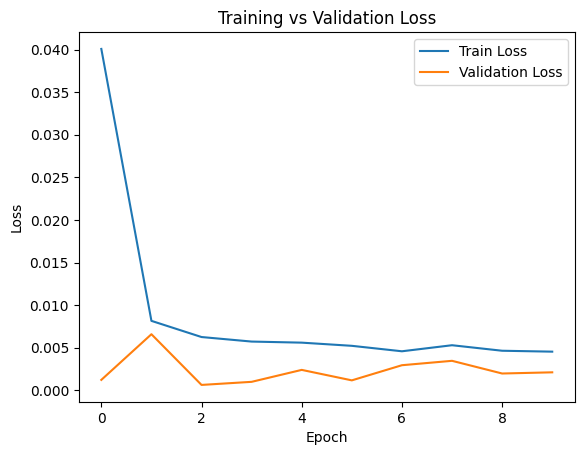

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

#GRAFIK PERBANDINGAN

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

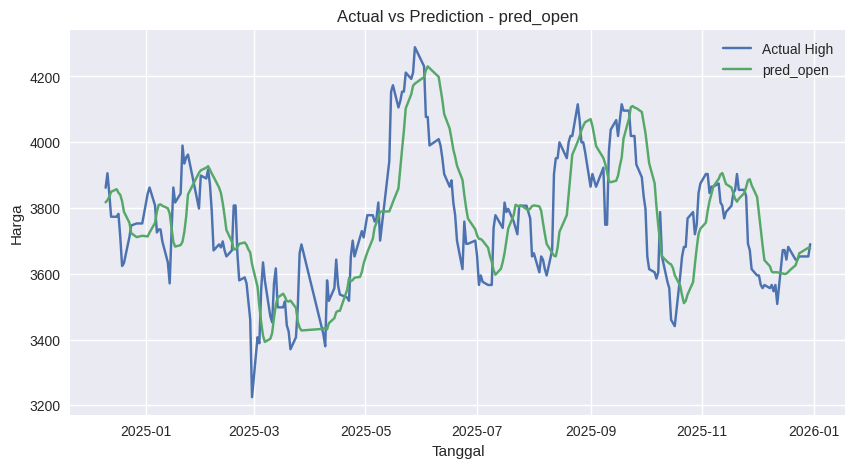

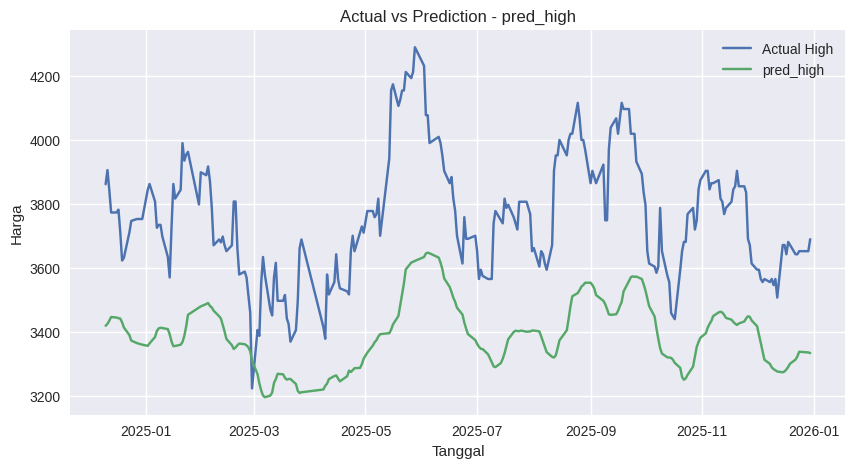

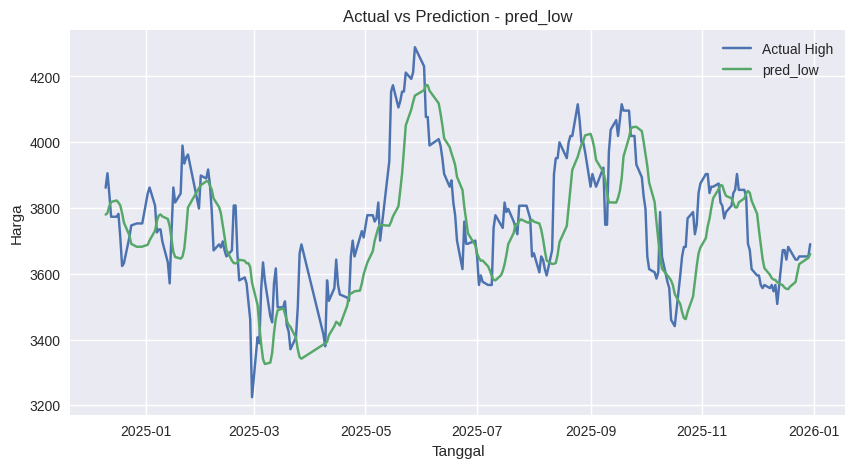

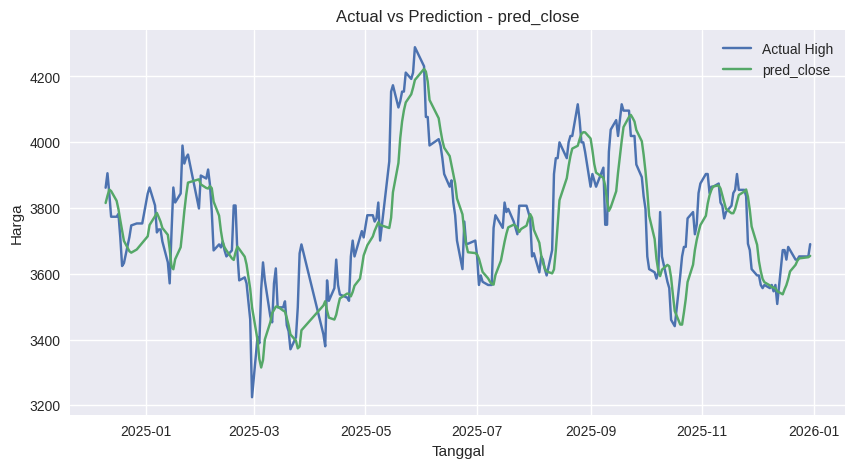

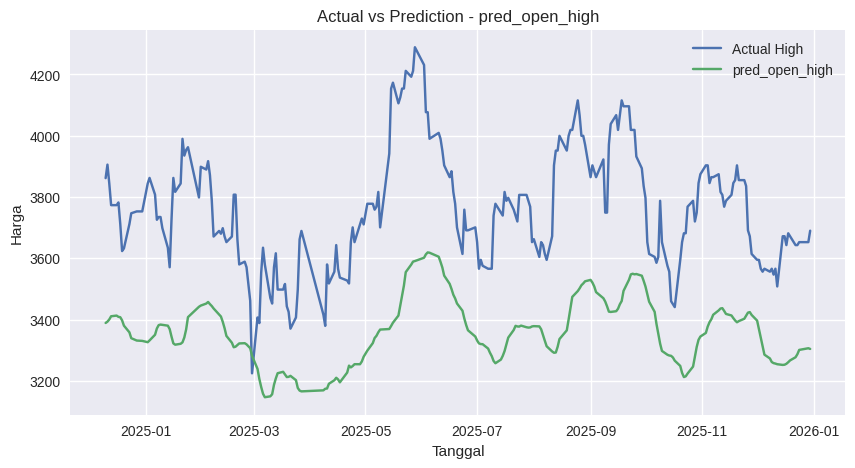

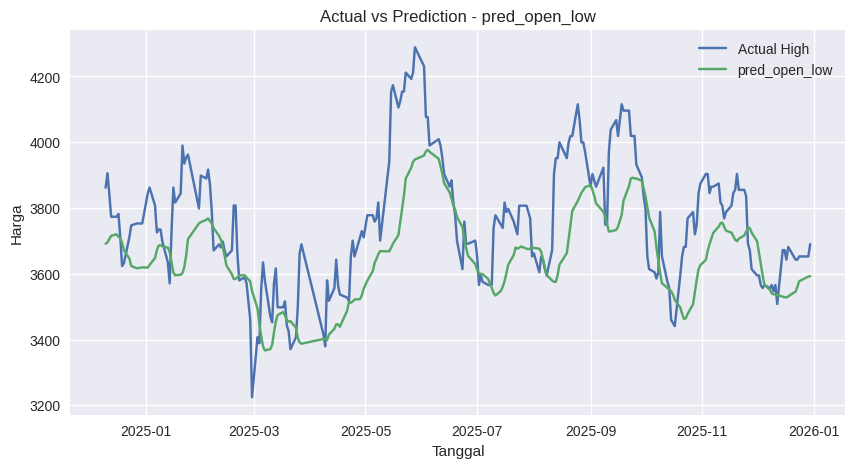

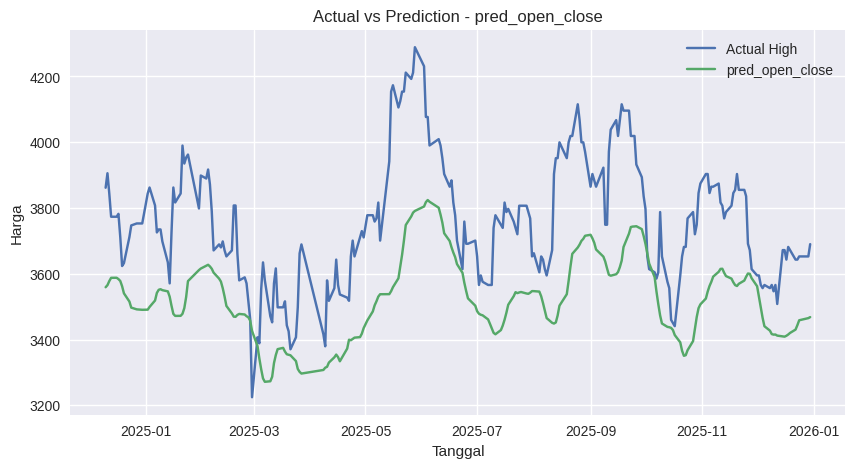

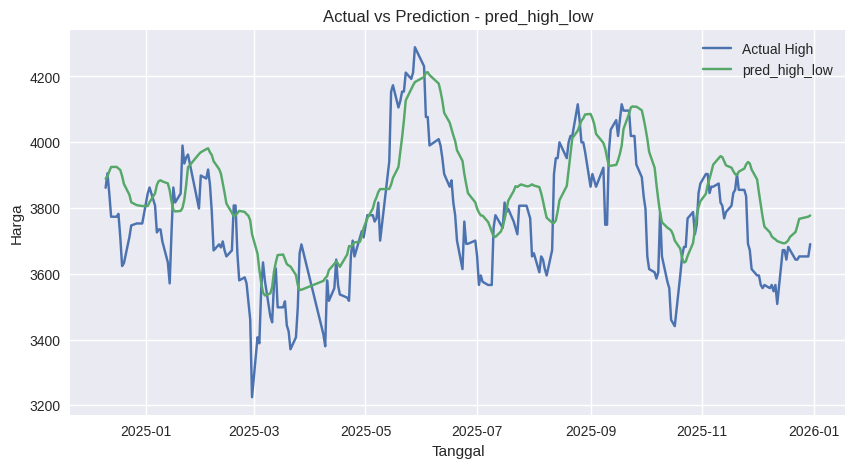

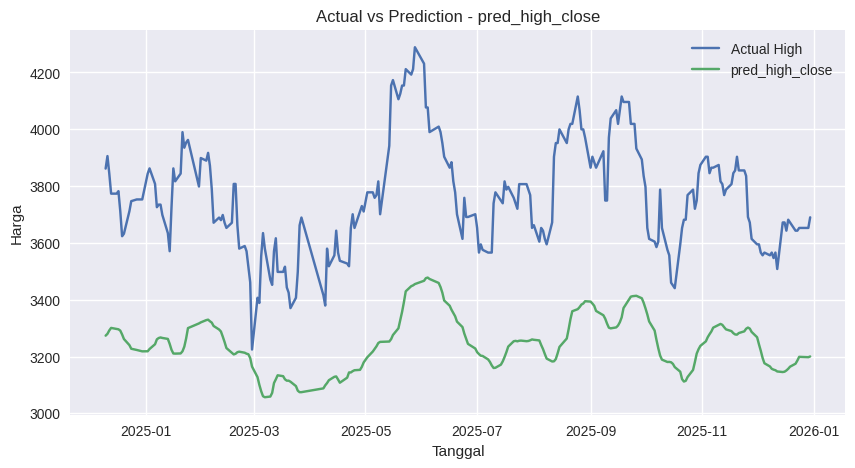

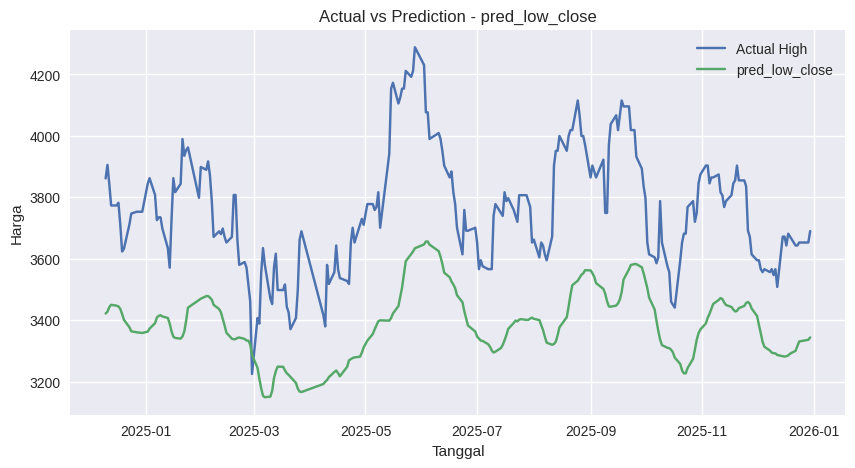

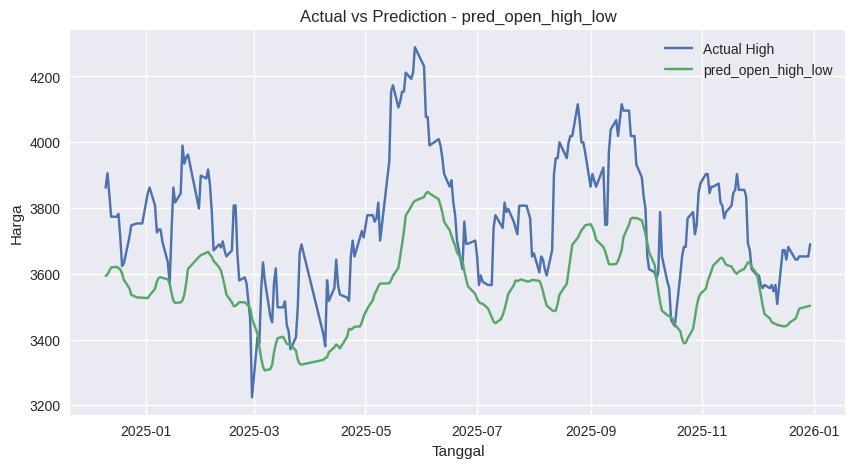

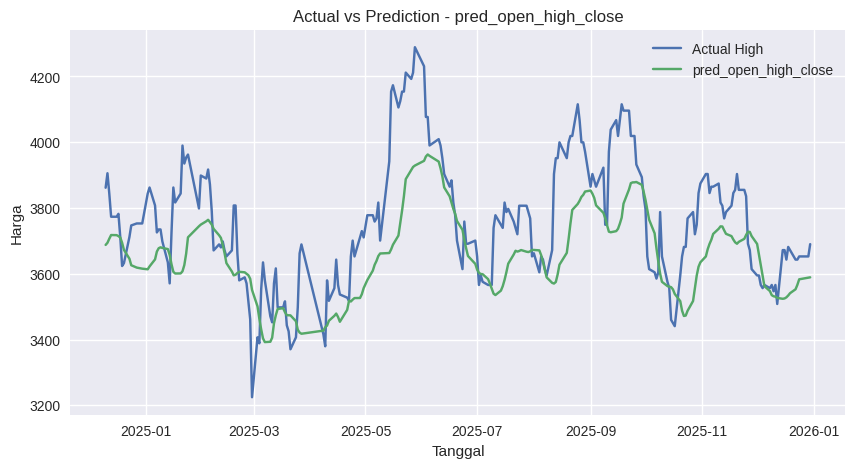

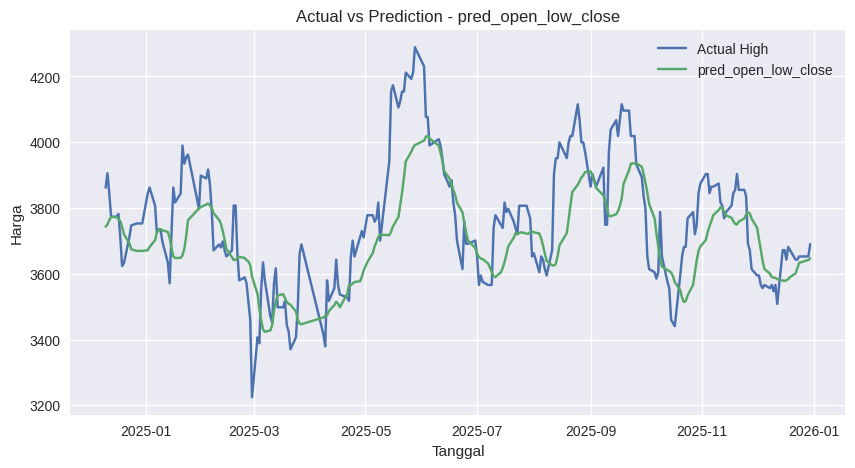

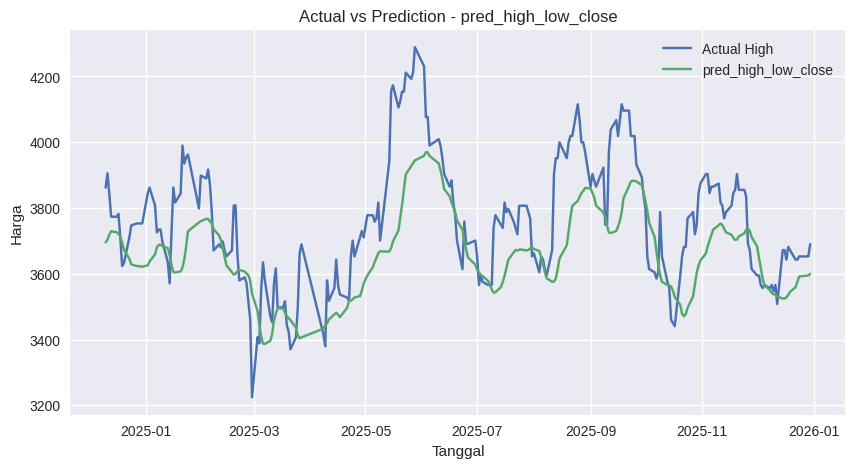

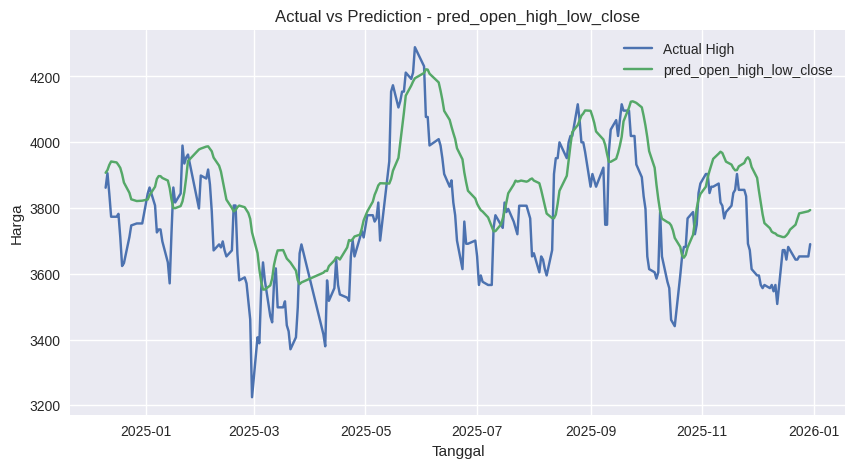

In [ ]:
#GANTI
import matplotlib.pyplot as plt

for col in prediction_columns:
    plt.style.use("seaborn-v0_8")
    plt.figure(figsize=(10,5))

    plt.plot(results_df["date"], results_df["actual_high"], label="Actual High")
    plt.plot(results_df["date"], results_df[col], label=col)

    plt.title(f"Actual vs Prediction - {col}")
    plt.xlabel("Tanggal")
    plt.ylabel("Harga")

    plt.legend()
    plt.grid(True)

    plt.show()

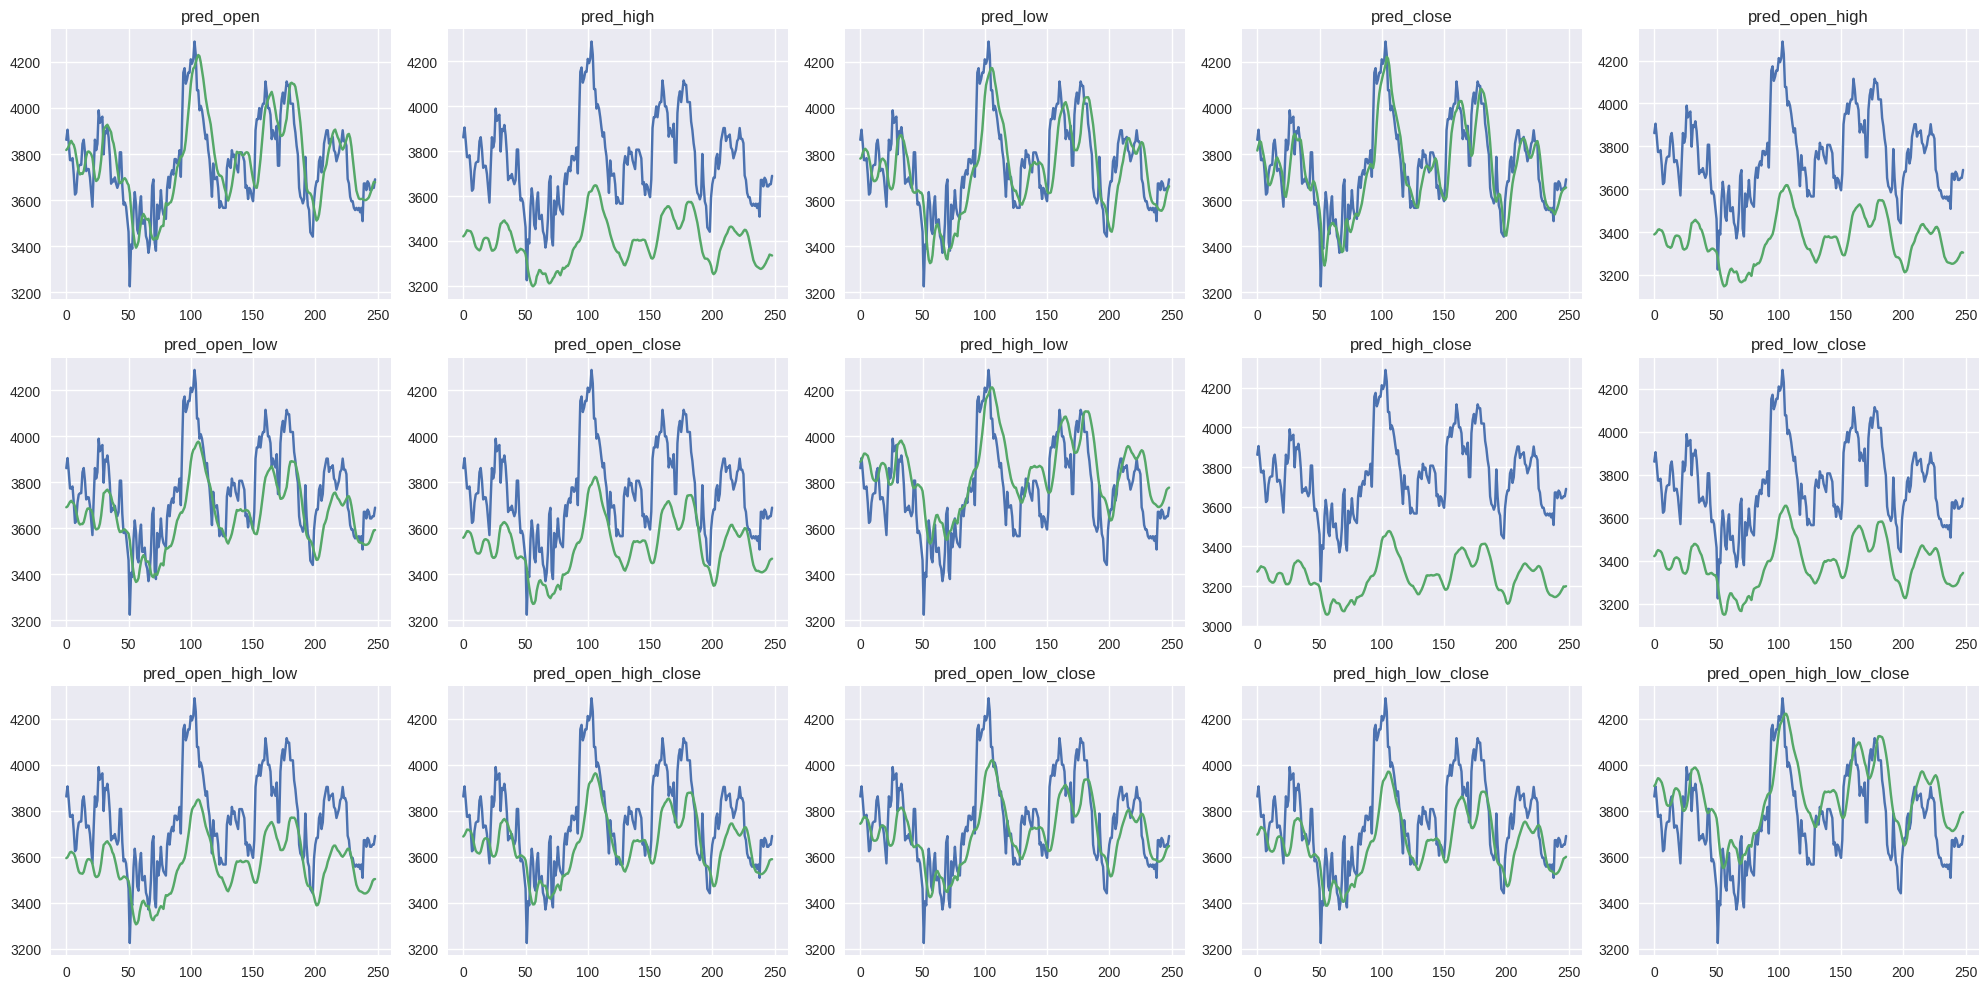

In [ ]:
#GANTI
fig, axes = plt.subplots(3,5, figsize=(20,10))
axes = axes.flatten()

for i, col in enumerate(prediction_columns):

    axes[i].plot(results_df["actual_high"], label="Actual")
    axes[i].plot(results_df[col], label="Prediksi")

    axes[i].set_title(col)
    axes[i].grid(True)

plt.style.use("seaborn-v0_8")
plt.tight_layout()
plt.show()

# MSE without DIFFERENCING

In [ ]:
prediction_columns = [
    'pred_open',
    'pred_high',
    'pred_low',
    'pred_close',
    'pred_open_high',
    'pred_open_low',
    'pred_open_close',
    'pred_high_low',
    'pred_high_close',
    'pred_low_close',
    'pred_open_high_low',
    'pred_open_high_close',
    'pred_open_low_close',
    'pred_high_low_close',
    'pred_open_high_low_close'
]

In [ ]:
#GANTI
import numpy as np
import pandas as pd

# Error setiap model
for col in prediction_columns:

    error_col = "error_" + col

    results_df[error_col] = (results_df["actual_high"] - results_df[col])**2


# MSE dan RMSE setiap model
evaluation_results = []

for col in prediction_columns:

    error_col = "error_" + col

    mse = results_df[error_col].mean()
    rmse = np.sqrt(mse)

    evaluation_results.append([col, mse, rmse])


# Membuat tabel evaluasi
tabel_evaluasi = pd.DataFrame(evaluation_results, columns=["Model", "MSE", "RMSE"])

print(tabel_evaluasi)

                       Model            MSE        RMSE
0                  pred_open   18934.485847  137.602638
1                  pred_high  149022.727786  386.034620
2                   pred_low   19513.055718  139.689140
3                 pred_close   11530.081060  107.378215
4             pred_open_high  174653.507327  417.915670
5              pred_open_low   27628.560708  166.218413
6            pred_open_close   70453.227553  265.430269
7              pred_high_low   23895.247681  154.580877
8            pred_high_close  277975.111317  527.233450
9             pred_low_close  153972.490576  392.393286
10        pred_open_high_low   56014.592485  236.674022
11      pred_open_high_close   27513.098441  165.870728
12       pred_open_low_close   19002.869328  137.850895
13       pred_high_low_close   25590.196574  159.969361
14  pred_open_high_low_close   25687.784596  160.274092


In [ ]:
# Urutan model terbaik berdasarkan MSE

tabel_evaluasi = tabel_evaluasi.sort_values(by="MSE")
print(tabel_evaluasi)

                       Model            MSE        RMSE
3                 pred_close   11530.081060  107.378215
0                  pred_open   18934.485847  137.602638
12       pred_open_low_close   19002.869328  137.850895
2                   pred_low   19513.055718  139.689140
7              pred_high_low   23895.247681  154.580877
13       pred_high_low_close   25590.196574  159.969361
14  pred_open_high_low_close   25687.784596  160.274092
11      pred_open_high_close   27513.098441  165.870728
5              pred_open_low   27628.560708  166.218413
10        pred_open_high_low   56014.592485  236.674022
6            pred_open_close   70453.227553  265.430269
1                  pred_high  149022.727786  386.034620
9             pred_low_close  153972.490576  392.393286
4             pred_open_high  174653.507327  417.915670
8            pred_high_close  277975.111317  527.233450


# PREDIKSI 7 HARI KE DEPAN

In [ ]:
#GANTI
last_sequence = X_test_close[-1]
last_sequence

array([[0.76579123],
       [0.77251763],
       [0.77028147],
       [0.7680393 ],
       [0.77028147],
       [0.77028147],
       [0.77251763]])

In [ ]:
#GANTI
future_predictions = []

current_sequence = last_sequence.copy()

for i in range(8):

    pred = models["open"].predict(current_sequence.reshape(1, current_sequence.shape[0], current_sequence.shape[1]))

    future_predictions.append(pred[0,0])

    # update window
    current_sequence = np.roll(current_sequence, -1, axis=0)

    # masukkan prediksi ke timestep terakhir
    current_sequence[-1, 0] = pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step

/tmp/ipykernel_478/1529551275.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  current_sequence[-1, 0] = pred


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


In [ ]:
#GANTI
future_predictions = np.array(future_predictions).reshape(-1,1)

# inverse scaler
future_log = scaler_high.inverse_transform(future_predictions)

# inverse log
future_prices = np.exp(future_log)

future_prices = future_prices.flatten()

In [ ]:
print("Prediksi harga saham 7 hari ke depan:")

for i, price in enumerate(future_prices, start=1):
    print(f"Hari ke-{i}: {price:.2f}")

Prediksi harga saham 7 hari ke depan:
Hari ke-1: 3715.72
Hari ke-2: 3719.99
Hari ke-3: 3721.81
Hari ke-4: 3725.97
Hari ke-5: 3731.97
Hari ke-6: 3737.28
Hari ke-7: 3743.10
Hari ke-8: 3748.27
